# AI AGENT VS AGENTIC AI

In [4]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain.agents import create_agent

agent = create_agent(
    model = "gpt-4o-mini",
    tools = [],
     system_prompt = "You are a helpful assistant that can answer questions about the world."
)

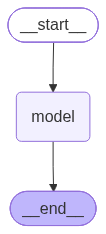

In [5]:
agent

In [7]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain.agents import create_agent

def get_weather():
    """ A simple tool that returns the current weather."""
    return "The weather is sunny with a high of 75°F."

agent = create_agent(
    model = "gpt-4o-mini",
    tools = [get_weather],
     system_prompt = "You are a helpful assistant that can answer questions about the world."
)

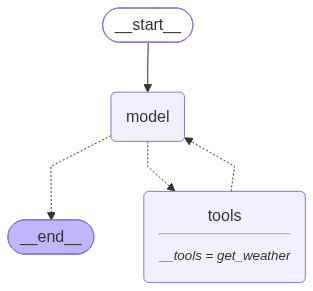

In [8]:
agent

In [11]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
from langchain_groq import ChatGroq

llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)

In [12]:
llm.invoke("What is the weather like today?")

AIMessage(content='I’m not able to access real‑time weather data, so I can’t tell you the current conditions for any location. If you let me know the city or region you’re interested in, I can give you typical climate information for this time of year and suggest reliable sources (such as weather.com, the National Weather Service, or a local news outlet) where you can check the up‑to‑date forecast.', additional_kwargs={'reasoning_content': 'The user asks "What is the weather like today?" No location given. As an AI, we don\'t have real-time data. We need to respond that I cannot provide real-time weather, suggest checking a weather service, ask for location. Also comply with policies.'}, response_metadata={'token_usage': {'completion_tokens': 147, 'prompt_tokens': 78, 'total_tokens': 225, 'completion_time': 0.311227489, 'completion_tokens_details': {'reasoning_tokens': 54}, 'prompt_time': 0.004845574, 'prompt_tokens_details': None, 'queue_time': 1.738765589, 'total_time': 0.316073063},

In [13]:
llm.invoke("What is ramyana movie collection in 2026.?")

AIMessage(content='I’m not aware of any publicly‑available box‑office figures for a film titled **“Ramyana”** (or a similarly‑spelled “Ramayana”) that would cover the year\u202f2026. As of my latest update (late\u202f2024) there is no record of a movie by that exact name having been released, let alone a collection for a future year.\n\nIf you’re referring to one of the following, here’s what is known up to now:\n\n| Film (Year) | Region / Language | Release Status (as of\u202f2024) | Box‑office (approx.) |\n|-------------|-------------------|----------------------------|----------------------|\n| **Ramayana: The Legend of Prince Rama** (1992, animated) | International (English/Japanese) | Already released (classic) | ~\u202f$4\u202fmillion worldwide (historical) |\n| **Ramayan** (2022, Hindi) | India (Bollywood) | Released on Disney+ Hotstar (direct‑to‑stream) – no theatrical gross reported | N/A (streaming‑only) |\n| **Ramayana** (2023, Tamil) | India (Tamil) | Limited theatrical run

In [14]:
import json
from typing import Optional
from duckduckgo_search import DDGS

def search_live_news(query: str, max_results: int = 5, timelimit: Optional[str] = "d") -> str:
    """
    Fetches real-time news articles from DuckDuckGo.

    Args:
        query (str): The search topic or headline keyword (e.g., "tech layoffs", "market updates").
        max_results (int): Number of news articles to retrieve (default: 5).
        timelimit (str, optional): Time range filter.
            - "d": Past day (recommended for breaking/live news)
            - "w": Past week
            - "m": Past month
            - None: No time restriction

    Returns:
        str: JSON string containing a list of news items with title, url, snippet, date, and source.
    """
    try:
        with DDGS() as ddgs:
            # Query the dedicated news endpoint
            results = list(
                ddgs.news(
                    keywords=query,
                    region="wt-wt",        # Worldwide; use "us-en", "uk-en", etc. if needed
                    safesearch="moderate",
                    timelimit=timelimit,
                    max_results=max_results,
                )
            )

        if not results:
            return json.dumps({"status": "empty", "message": f"No live news found for '{query}'."})

        # Standardize output for the agent context
        formatted_results = []
        for item in results:
            formatted_results.append({
                "title": item.get("title"),
                "url": item.get("url"),
                "date": item.get("date"),
                "source": item.get("source"),
                "snippet": item.get("body"),
            })

        return json.dumps({"status": "success", "results": formatted_results}, indent=2)

    except Exception as e:
        return json.dumps({"status": "error", "message": str(e)})


# Quick verification
if __name__ == "__main__":
    news_json = search_live_news("Artificial Intelligence breakthroughs", max_results=3, timelimit="d")
    print(news_json)

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


{
  "status": "success",
  "results": [
    {
      "title": "Hope and fear: Voters from across the country share their feelings about the burgeoning realm of AI",
      "url": "https://www.deseret.com/business/2026/11/09/national-polling-ai-artificial-intelligence-privacy-data-misuse-medical-scientific-advances-job-losses-human-control-environmental-costs/",
      "date": "2026-11-09T04:00:00+00:00",
      "source": "Deseret News",
      "snippet": "Utahns are particularly worried about privacy issues, while national audience is most concerned about humans losing control of AI. Future medical and scientific advances, driven by AI, are among the top reasons for optimism."
    },
    {
      "title": "Google advances agentic AI custom silicon expanding TPU family with 8tx and 8i Max",
      "url": "https://siliconangle.com/2026/11/09/google-advances-agentic-ai-custom-silicon-expanding-tpu-family-with-8tx-and-8i-max/",
      "date": "2026-11-09T13:00:00+00:00",
      "source": "SiliconAN

In [15]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
from langchain_groq import ChatGroq

llm = ChatGroq(
    model = "openai/gpt-oss-120b"
)



from langchain.agents import create_agent

agent = create_agent(
    model = llm,
    tools = [search_live_news],
     system_prompt = "You are a helpful assistant that can answer questions about the world."   
)




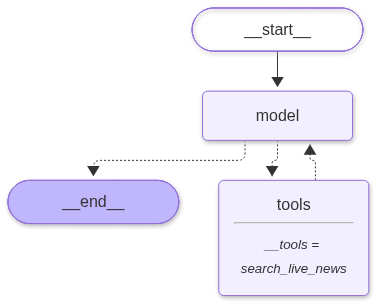

In [16]:
agent

In [18]:
agent.invoke({"input": "What is the capital of France?"})

{'messages': [AIMessage(content='Sure! How can I help you today?', additional_kwargs={'reasoning_content': "The user hasn't asked a question yet. The system message says answer questions about world. No user query. Possibly need to wait for user question. There's no request. Probably need to respond asking how can help."}, response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 288, 'total_tokens': 349, 'completion_time': 0.128494209, 'completion_tokens_details': {'reasoning_tokens': 43}, 'prompt_time': 0.021643185, 'prompt_tokens_details': None, 'queue_time': 0.376977273, 'total_time': 0.150137394}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e1a78f200e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c117-953f-7290-8311-6dff1e029c52-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 288, 'output_tokens': 61, 'total_tokens': 349, 'output_token_details': {'

In [ ]:
response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "current layoffs in ",
            }
        ]
    }
    
)

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`

In [22]:
response


{'messages': [HumanMessage(content='What is bollywood Ramayana movie collection in 2026.?', additional_kwargs={}, response_metadata={}, id='2be2de63-5faf-4e3c-98f3-ca82001d8132'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is bollywood Ramayana movie collection in 2026.?" Likely they want box office collection for a Bollywood movie titled "Ramayana" released in 2026? But as of now (2026 current date) maybe a Bollywood adaptation of Ramayana released? Need real-time info. Use news search.', 'tool_calls': [{'id': 'fc_49452fce-8b1c-4499-a2ca-3b8302fce9cb', 'function': {'arguments': '{"max_results":10,"query":"Bollywood Ramayana movie 2026 box office collection","timelimit":"y"}', 'name': 'search_live_news'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 125, 'prompt_tokens': 305, 'total_tokens': 430, 'completion_time': 0.262945564, 'completion_tokens_details': {'reasoning_tokens': 70}, 'prompt_time': 0.042541592, 

In [27]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")

from langchain_ollama import ChatOllama


llm = ChatOllama(
    model = "mistral:latest"
)



from langchain.agents import create_agent

agent = create_agent(
    model = llm,
    tools = [search_live_news],
     system_prompt = "You are a helpful assistant that can answer questions about the world."   
)




/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/3469893947.py:18: ResourceWarning: unclosed <socket.socket fd=107, family=2, type=1, proto=6, laddr=('127.0.0.1', 56330), raddr=('127.0.0.1', 11434)>
  agent = create_agent(


In [26]:

llm.invoke("Hi")

AIMessage(content=" Hello! How can I assist you today?\n\nI am here to help answer questions, provide information, or engage in friendly conversation. If you have any topics you'd like to discuss or questions you'd like me to help with, just let me know.\n\nFor example, you could ask me about science, history, literature, or even just ask for a fun fact or a joke. I'm here to make your day a little bit brighter!\n\nHow can I help you today? 😊", additional_kwargs={}, response_metadata={'model': 'mistral:latest', 'created_at': '2026-11-09T16:23:17.135082Z', 'done': True, 'done_reason': 'stop', 'total_duration': 13703776458, 'load_duration': 6529340333, 'prompt_eval_count': 5, 'prompt_eval_duration': 203441000, 'eval_count': 109, 'eval_duration': 6940646000, 'logprobs': None, 'model_name': 'mistral:latest', 'model_provider': 'ollama'}, id='lc_run--01a1c11e-cbfe-71f1-b26a-fd01ea3a4abd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 109, 'total_

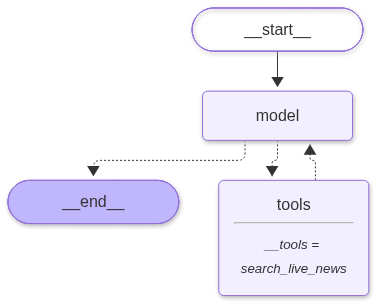

In [28]:
agent

In [29]:
response = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "current layoffs in microsoft",
            }
        ]
    }
    
)

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_82573/2549988500.py:22: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


In [30]:
response

{'messages': [HumanMessage(content='current layoffs in microsoft', additional_kwargs={}, response_metadata={}, id='d466d494-ed9c-4aee-aab8-6960c79ea260'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'mistral:latest', 'created_at': '2026-11-09T16:24:29.779036Z', 'done': True, 'done_reason': 'stop', 'total_duration': 36367447750, 'load_duration': 20591542, 'prompt_eval_count': 249, 'prompt_eval_duration': 1556956000, 'eval_count': 556, 'eval_duration': 34776039000, 'logprobs': None, 'model_name': 'mistral:latest', 'model_provider': 'ollama'}, id='lc_run--01a1c11f-8f23-7203-93b9-2ad294c1311f-0', tool_calls=[{'name': 'search_live_news', 'args': {'query': 'microsoft layoffs', 'max_results': 3, 'timelimit': 'd'}, 'id': '29c248d5-e85e-48ca-a1b9-bf01bf65f6cb', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 249, 'output_tokens': 556, 'total_tokens': 805}),
  ToolMessage(content='{"status": "error", "message": "https://duckduckgo.com/n